<a href="https://colab.research.google.com/github/poojagupthaa14/OIBSIP/blob/main/task1_retail_saales_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the retail sales dataset
df = pd.read_csv("/content/retail_sales_dataset.csv")

# Display the first 5 rows
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
# Check the number of rows and columns
df.shape

(1000, 9)

In [6]:
# Display all column names
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

In [7]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [8]:
# Count missing values in each column
df.isnull().sum()

,0
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


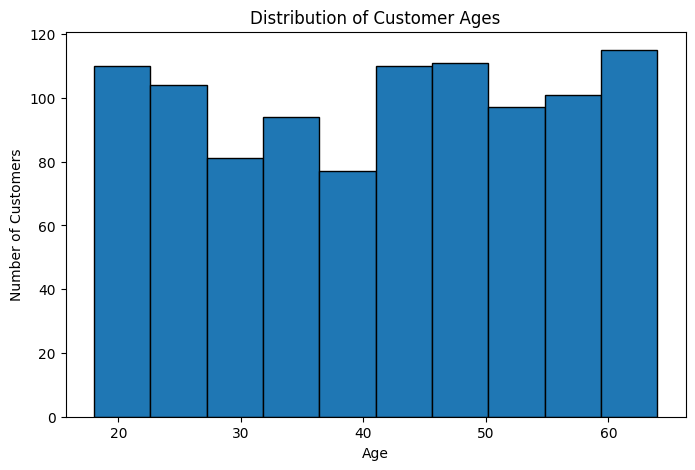

In [9]:

# Create a histogram of customer ages
plt.figure(figsize=(8, 5))

plt.hist(df['Age'], bins=10, edgecolor='black')

plt.title('Distribution of Customer Ages')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()


### Customer Age Distribution

A histogram was created to understand the distribution of customer ages.

The visualization helps identify the age groups that contribute most to retail transactions and shows how customer ages are spread across the dataset.

This information can help the business understand its customer demographics and plan targeted marketing strategies.

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


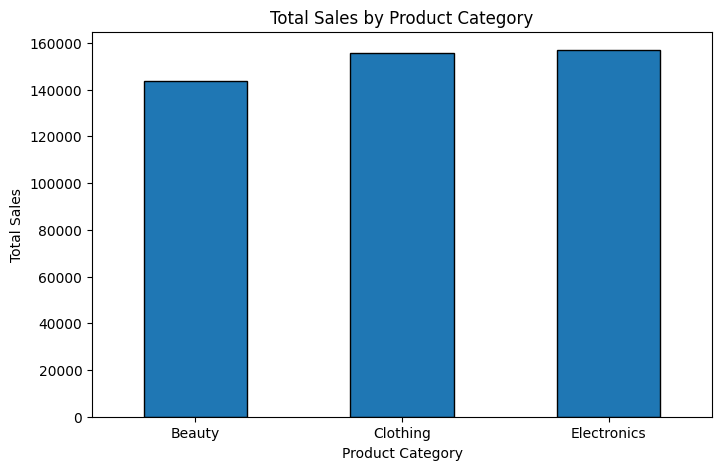

In [10]:

# Calculate total sales for each product category
category_sales = df.groupby('Product Category')['Total Amount'].sum()

# Display sales by category
print(category_sales)

# Create a bar chart
plt.figure(figsize=(8, 5))

category_sales.plot(kind='bar', edgecolor='black')

plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()


### Sales by Product Category

A bar chart was created to compare the total revenue generated by different product categories.

The chart helps identify the highest-performing and lowest-performing categories. This information can help the business make better inventory, marketing, and sales decisions.

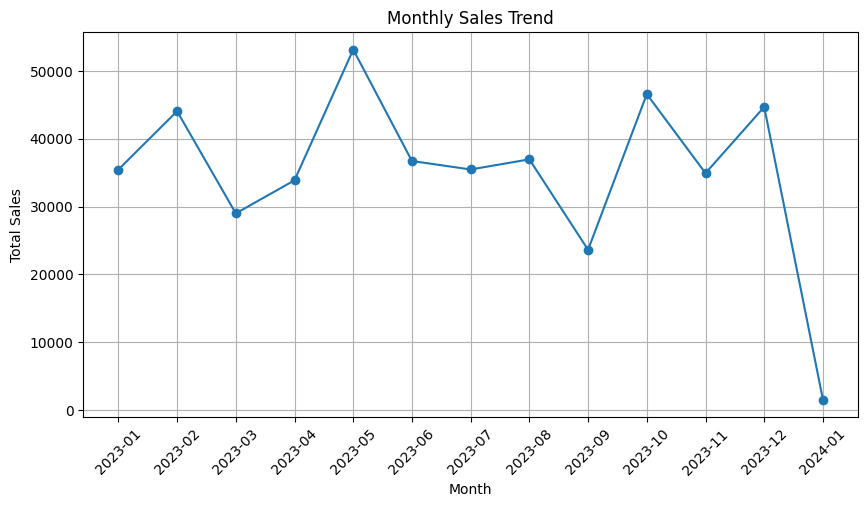

In [11]:

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Calculate monthly sales
monthly_sales = df.groupby(
    df['Date'].dt.to_period('M')
)['Total Amount'].sum()

# Create a line chart
plt.figure(figsize=(10, 5))

plt.plot(monthly_sales.index.astype(str),
         monthly_sales.values,
         marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)

plt.show()


### Monthly Sales Trend

A line chart was created to analyze monthly retail sales over time.

The visualization helps identify months with higher and lower sales and reveals changes in sales performance across the observed period.

These trends can help businesses plan inventory, promotions, and sales strategies more effectively.

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


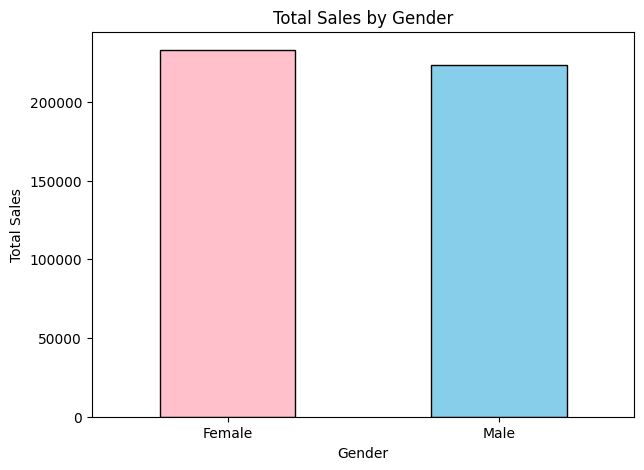

In [12]:

# Calculate total sales by gender
gender_sales = df.groupby('Gender')['Total Amount'].sum()

# Display the results
print(gender_sales)

# Create a bar chart
plt.figure(figsize=(7, 5))

gender_sales.plot(kind='bar', color=['pink', 'skyblue'],
                  edgecolor='black')

plt.title('Total Sales by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()


### Sales Analysis by Gender

A bar chart was created to compare total sales generated by male and female customers.

The visualization helps identify differences in purchasing contributions between the two customer groups. These insights can help businesses understand customer behavior and develop targeted marketing strategies.

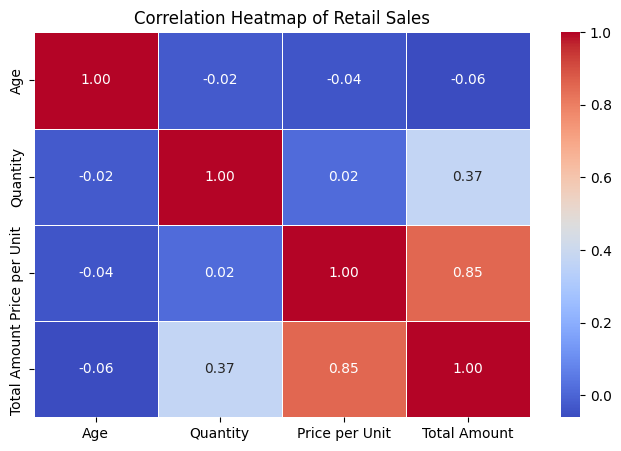

In [13]:

# Select meaningful numerical columns
numerical_data = df[['Age', 'Quantity',
                     'Price per Unit', 'Total Amount']]

# Calculate correlation
correlation = numerical_data.corr()

# Create a heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(correlation,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            linewidths=0.5)

plt.title('Correlation Heatmap of Retail Sales')
plt.show()


### Correlation Heatmap

A correlation heatmap was created to examine the relationships between numerical variables in the retail sales dataset.

The visualization helps identify positive and negative relationships between variables. These relationships can provide useful insights into customer purchasing behavior and sales patterns.

Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64


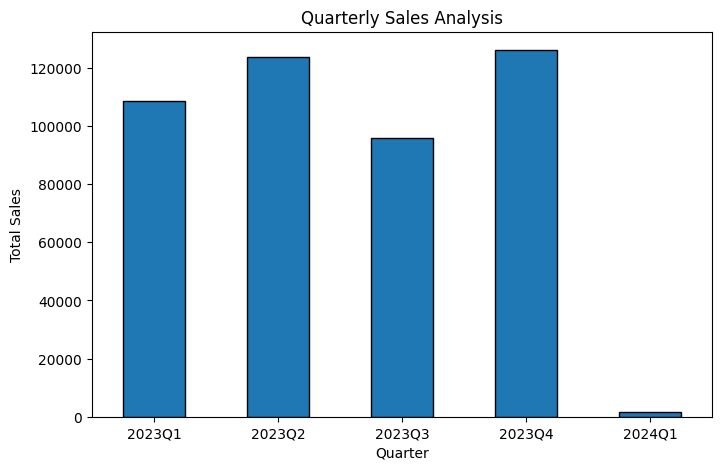

In [14]:

# Extract quarter from the Date column
df['Quarter'] = df['Date'].dt.to_period('Q')

# Calculate total sales for each quarter
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

# Display quarterly sales
print(quarterly_sales)

# Create a bar chart
plt.figure(figsize=(8, 5))

quarterly_sales.plot(kind='bar', edgecolor='black')

plt.title('Quarterly Sales Analysis')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()


### Quarterly Sales Analysis

A bar chart was created to compare total retail sales across different quarters.

The visualization helps identify periods of stronger and weaker sales performance. Quarterly analysis can help businesses plan inventory, marketing campaigns, and resource allocation.

## Conclusion and Business Insights

The exploratory data analysis of the retail sales dataset helped identify patterns in customer demographics, product category performance, and sales trends.

### Key Findings
1. Customer age distribution provides insights into the age groups contributing to retail transactions.
2. Product category analysis identifies the categories generating the highest revenue.
3. Monthly and quarterly sales analysis reveals changes in sales performance over time.
4. Gender-based analysis helps compare purchasing contributions between customer groups.
5. Correlation analysis helps understand relationships between numerical variables.

### Business Recommendations
- Focus marketing strategies on customer groups that contribute significantly to sales.
- Maintain sufficient inventory for high-performing product categories.
- Use monthly and quarterly sales trends to plan promotional campaigns.
- Monitor sales performance regularly to identify opportunities for improvement.

### Conclusion
This project demonstrates how Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn can be used to analyze retail sales data and generate meaningful business insights.


## Key Findings from Retail Sales Analysis

1. **Product Performance:** Electronics generated the highest total revenue of 156,905, followed by Clothing at 155,580. Beauty generated the lowest revenue of 143,515.

2. **Monthly Sales:** May 2023 recorded the highest monthly sales, totaling 53,150.

3. **Customer Gender:** Female customers contributed 232,840 in sales, while male customers contributed 223,160.

4. **Quarterly Performance:** Q4 2023 recorded the highest quarterly sales of 126,190.

### Business Recommendations

- Maintain adequate inventory for Electronics and Clothing due to their strong sales performance.
- Investigate the factors contributing to the high sales in May and Q4.
- Explore marketing strategies to improve Beauty category sales.
- Analyze customer purchasing patterns to create targeted promotions.

### Conclusion

The analysis identified useful patterns in product performance, customer purchasing behavior, and sales trends. These insights can help businesses improve inventory management, marketing strategies, and sales planning.
